# Giorno 2, mattina: pandas essenziale

Obiettivo di oggi: sostituire un intero foglio Excel con quindici righe di codice.

Ieri avete costruito una tabella con liste e cicli, e l'avete salvata in CSV a mano.
Oggi vedrete che pandas fa tutto questo con una riga, e molto altro: filtri, colonne
calcolate, raggruppamenti, unioni fra tabelle. Il vantaggio non è solo la velocità.
Il procedimento resta **scritto**: si rilegge, si ripete su un file nuovo, si corregge
in un punto solo.

## 0. Cella di avvio

In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def trova_dati():
    for cand in [Path("../dati"), Path("dati"), Path("corso_python_CNR/dati")]:
        if cand.exists():
            return cand
    for radice in [Path(".."), Path("."), Path("corso_python_CNR")]:
        if (radice / "genera_dati.py").exists():
            sys.path.insert(0, str(radice.resolve()))
            from genera_dati import genera_tutto
            return genera_tutto(radice / "dati")
    raise FileNotFoundError("Cartella 'dati' non trovata: carica la cartella del corso.")

DATI = trova_dati()
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
print("pandas", pd.__version__)

---
## 1. `DataFrame` e `Series`

Un **DataFrame** è una tabella: righe con un'etichetta (l'*index*), colonne con un nome.
Ogni colonna è una **Series** con un solo tipo (`dtype`): numeri, testo, date. Corrisponde a
un foglio Excel ben fatto (una riga per osservazione, una colonna per variabile), ma con
i tipi dichiarati invece che indovinati cella per cella.

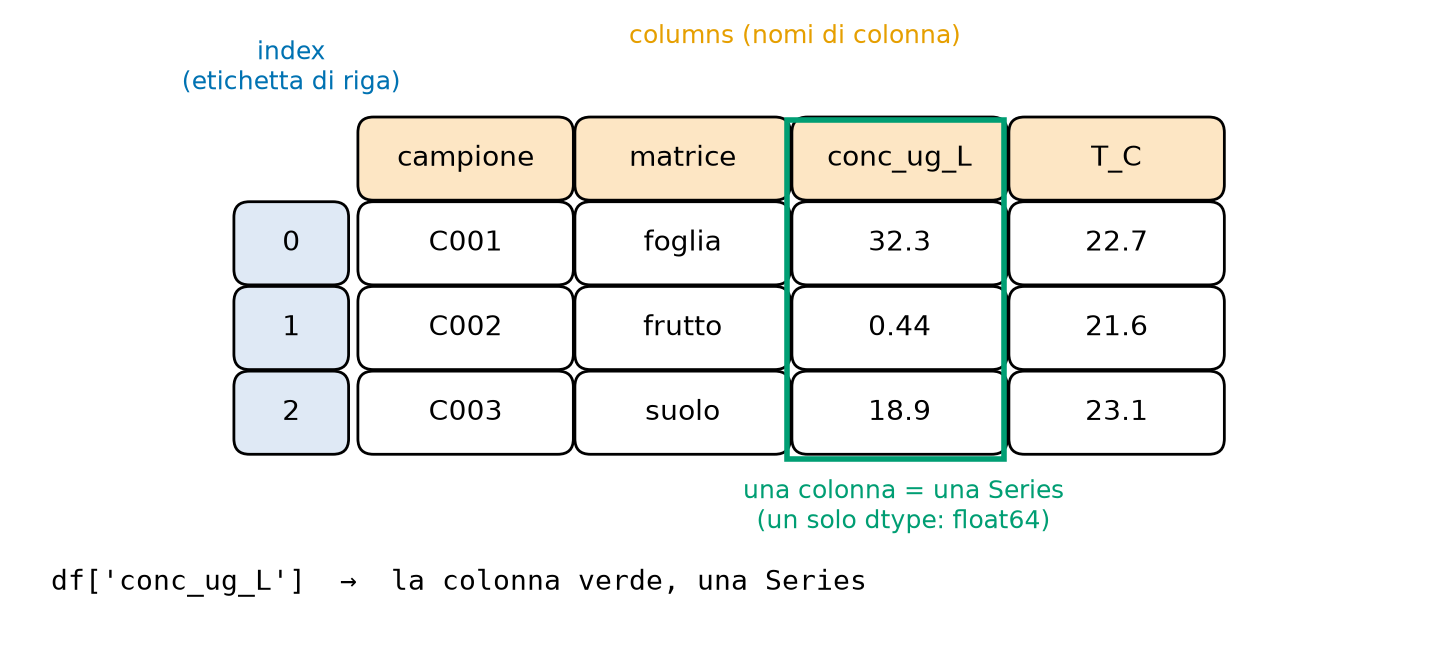

In [ ]:
# Da un dizionario di liste (una chiave = una colonna)
df = pd.DataFrame({
    "campione": ["C001", "C002", "C003", "C004"],
    "matrice": ["foglia", "frutto", "suolo", "foglia"],
    "conc_ug_L": [32.3, 0.44, 18.9, 29.1],
    "T_C": [22.7, 21.6, 23.1, 22.4],
})
df

In [ ]:
print(type(df), type(df["conc_ug_L"]))
print(df.shape)              # (righe, colonne)
print(df.columns.tolist())
print(df.dtypes)

In [ ]:
# Una colonna si comporta come un array NumPy, con qualcosa in più
print(df["conc_ug_L"].mean())
print(df["conc_ug_L"] * 2)            # l'indice viene conservato

---
## 2. Leggere il file di ieri: una riga

In [ ]:
# Il file scritto ieri pomeriggio (esercizio 2.4). Se non è nella cartella corrente, lo ricostruiamo.
riassunto = pd.read_csv("riassunto_dpv.csv") if Path("riassunto_dpv.csv").exists() else None
if riassunto is None:
    # se il file di ieri non è nella cartella corrente, lo ricostruiamo al volo
    righe = []
    for f in sorted((DATI / "strumento").glob("DPV_S??.txt")):
        meta, E, i = {}, [], []
        for r in f.read_text(encoding="utf-8").splitlines():
            if r.startswith("#"):
                k, v = r.split(":", 1); meta[k.strip("# ")] = v.strip()
            elif r and not r.startswith("E("):
                e, c = r.split("\t"); E.append(float(e)); i.append(float(c))
        E, i = np.array(E), np.array(i)
        righe.append([meta["Campione"], meta["Matrice"], float(meta["Concentrazione nominale (uM)"]),
                      E[i.argmax()], i.max() - i[E < -0.45].mean()])
    riassunto = pd.DataFrame(righe, columns=["campione", "matrice", "conc_nominale_uM", "E_picco_V", "i_picco_uA"])
riassunto

---
## 3. `read_csv` su dati reali sporchi

I file puliti come quello sopra sono rari. Quello esportato dal laboratorio ha:
- tre righe di commento in testa,
- `;` come separatore e la virgola come decimale (formato italiano),
- caratteri accentati e simboli (`µ`, `°`) salvati in codifica latin-1 (Windows),
- la stringa `n.d.` al posto dei valori mancanti,
- date in formato `gg/mm/aaaa`.

Prima di leggerlo, guardiamolo com'è. Il primo passo è sempre **aprire il file come testo**.

In [ ]:
percorso = DATI / "misure_sporche.csv"
for r in percorso.read_text(encoding="latin-1").splitlines()[:7]:
    print(repr(r))

In [ ]:
# Primo tentativo ingenuo: guardate cosa succede
try:
    tentativo = pd.read_csv(percorso, encoding="latin-1")
except pd.errors.ParserError as errore:      # il tipo preciso, come ieri
    print(type(errore).__name__, "->", errore)

`Expected 1 fields in line 5, saw 3`: pandas ha usato la virgola come separatore.
Nella prima riga (il commento) non ce n'è nessuna (1 campo), nella riga 5 ne trova due, le
virgole decimali di concentrazione e temperatura (3 campi). Il messaggio è criptico, ma
descrive esattamente cosa è successo. Per ogni problema c'è un parametro:

| Problema | Parametro |
|---|---|
| separatore `;` | `sep=";"` |
| virgola decimale | `decimal=","` |
| codifica Windows | `encoding="latin-1"` (o `"cp1252"`) |
| righe di commento in testa | `comment="#"` oppure `skiprows=3` |
| valori mancanti scritti come testo | `na_values=["n.d."]` |
| date | leggere come testo e convertire dopo con `pd.to_datetime(..., format="%d/%m/%Y")` |

In [ ]:
df = pd.read_csv(percorso, sep=";", decimal=",", encoding="latin-1",
                 comment="#", na_values=["n.d."])
df.head()

## 4. Ispezione: le quattro domande da fare a ogni tabella

1. Quanto è grande? → `shape`
2. Che tipo hanno le colonne, e quanti valori mancano? → `info()`
3. Che numeri contiene? → `describe()`
4. Che categorie contiene? → `value_counts()` sulle colonne di testo

La risposta alla 2 è la più importante: una **colonna numerica letta come testo** è il segnale
che qualcosa nel file è sporco. Il testo compare come `str` (pandas ≥ 3, il nostro ambiente)
oppure come `object` (pandas 2.x, per esempio su Colab): il significato è lo stesso.

In [ ]:
print(df.shape)
df.info()

In [ ]:
# Esempio: dimentichiamo decimal="," -> la concentrazione diventa testo ("32,34" non è un numero)
sbagliato = pd.read_csv(percorso, sep=";", encoding="latin-1", comment="#", na_values=["n.d."])
sbagliato.dtypes

In [ ]:
df.describe()

In [ ]:
print(df["matrice"].value_counts())
print()
print(df["operatore"].value_counts())      # stessa persona scritta in tre modi: da pulire

### Rinominare le colonne e sistemare le date

I nomi con spazi, parentesi e simboli funzionano ma sono scomodi da scrivere: meglio nomi
corti, senza spazi. Le date vanno convertite in tipo `datetime`, altrimenti restano
testo e non si possono ordinare, filtrare per mese o sottrarre.

In [ ]:
df = df.rename(columns={"concentrazione (µg/L)": "conc_ug_L", "T (°C)": "T_C"})
df["data"] = pd.to_datetime(df["data"], format="%d/%m/%Y")
df.info()

In [ ]:
df["data"].min(), df["data"].max()

---
## 5. `read_excel` e scrittura

Excel si legge con `read_excel` (serve la libreria `openpyxl`, già nell'ambiente). Per
scrivere ci sono `to_csv` e `to_excel`. Mettete quasi sempre `index=False`, altrimenti vi
ritrovate una colonna in più con i numeri di riga.

In [ ]:
meta = pd.read_excel(DATI / "metadati_campioni.xlsx")
meta.head()

In [ ]:
meta.info()

In [ ]:
df.to_csv("misure_pulite_v0.csv", index=False)                  # separatore virgola, punto decimale
df.to_csv("misure_pulite_v0_it.csv", index=False, sep=";", decimal=",")   # per chi riapre in Excel italiano
df.to_excel("misure_pulite_v0.xlsx", index=False)
print("scritti 3 file nella cartella:", Path.cwd())

---
## 6. Selezione: righe e colonne

Ci sono diversi modi, da tenere ben distinti:

| Voglio… | Sintassi | Esempio |
|---|---|---|
| una colonna | `df["nome"]` | `df["conc_ug_L"]` |
| più colonne | `df[["a", "b"]]` (lista dentro le quadre) | `df[["campione", "conc_ug_L"]]` |
| righe/colonne per etichetta | `df.loc[righe, colonne]` | `df.loc[0:4, "campione":"analita"]` |
| righe/colonne per posizione | `df.iloc[righe, colonne]` | `df.iloc[0:5, 1:4]` |
| righe che soddisfano una condizione | `df[maschera]` | `df[df["conc_ug_L"] > 20]` |

Nota: con `.loc` gli estremi sono **inclusi** (`0:4` = 5 righe); con `.iloc` vale la regola
di Python (`0:5` = 5 righe, l'ultimo escluso). Qui sotto `loc` e `iloc` sembrano quasi uguali,
perché le etichette di riga coincidono con le posizioni (0, 1, 2…). La differenza vera si vede
dopo un filtro: tra poco.

In [ ]:
df[["campione", "analita", "conc_ug_L"]].head(3)

In [ ]:
df.loc[0:3, "campione":"analita"]

In [ ]:
df.iloc[0:3, 1:5]

### Filtri booleani

Funzionano come in NumPy: un confronto produce una maschera, la maschera seleziona le righe.
`&`, `|`, `~` con le parentesi. In più ci sono `.isin([...])` per "uno tra questi",
`.between(a, b)`, `.str.contains("...")` per il testo, `.isna()` per i mancanti.

In [ ]:
alto = df[df["conc_ug_L"] > 40]
print(len(alto), "misure sopra 40 µg/L")
alto.head()

### `loc` e `iloc` dopo un filtro

Guardate la colonna di sinistra di `alto`: le righe si chiamano 1, 3, 7, 32, 45… Il filtro
**conserva le etichette** della tabella originale. Da qui in poi etichetta e posizione non
coincidono più, ed è qui che `loc` e `iloc` danno risultati diversi.

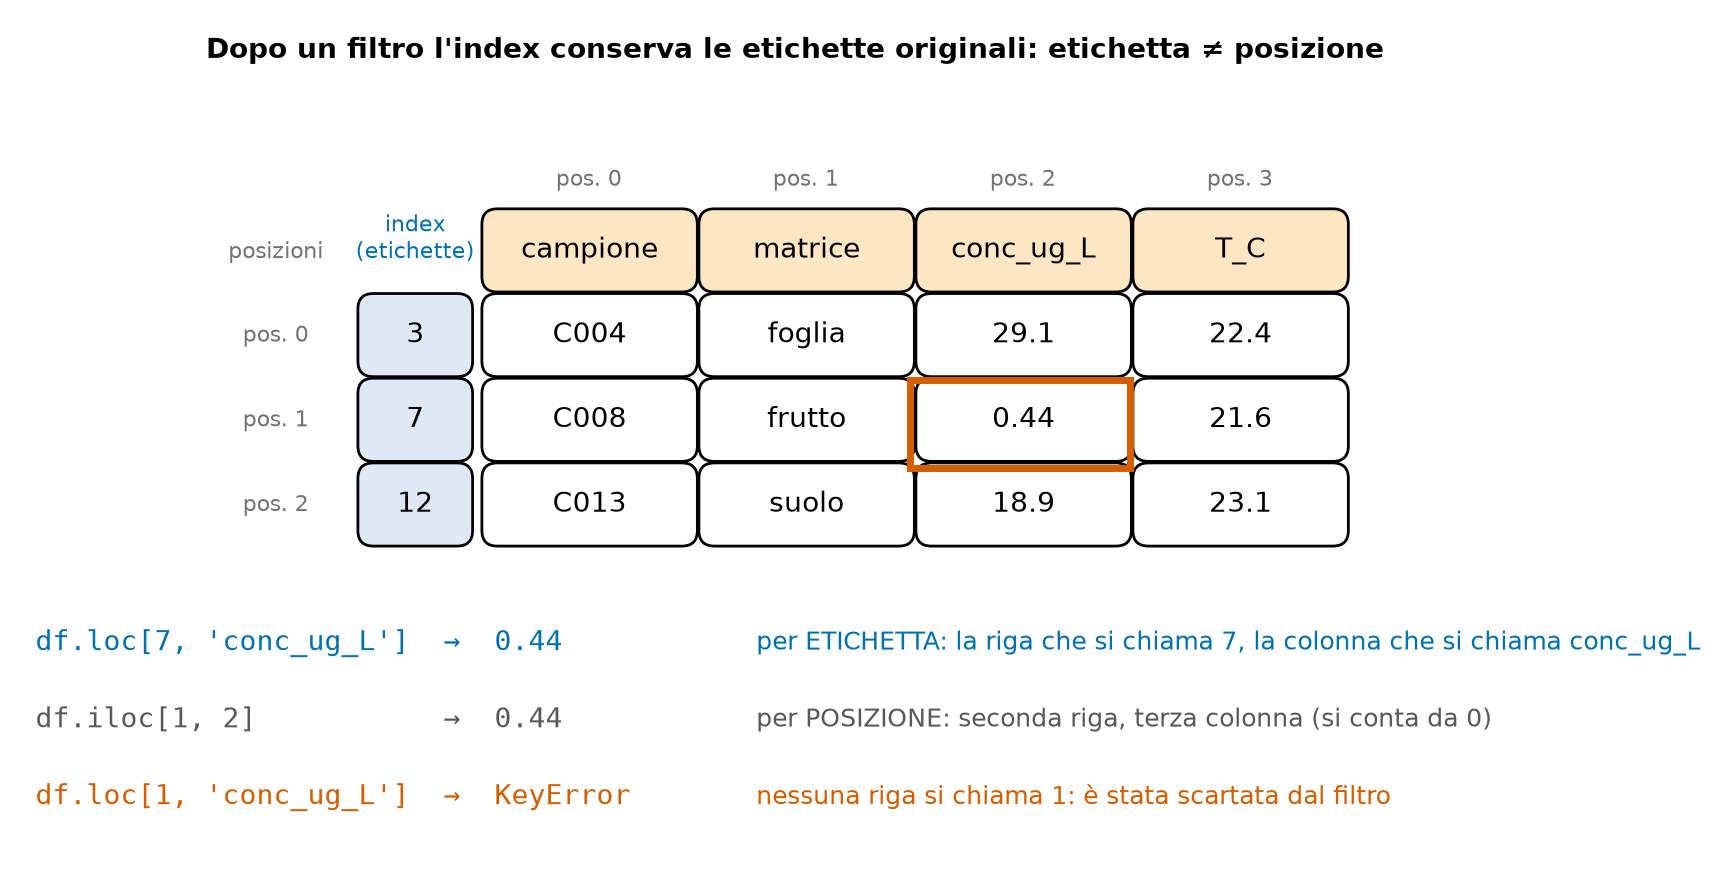

In [ ]:
print(alto.index[:5].tolist())                    # le etichette delle prime 5 righe di alto
print(alto.iloc[0, 1])                            # POSIZIONE 0, colonna in posizione 1 -> campione
print(alto.loc[1, "campione"])                    # ETICHETTA 1: è la stessa riga
print(alto.iloc[1, 1], alto.loc[3, "campione"])   # posizione 1 = etichetta 3
print(0 in alto.index)                            # False: alto.loc[0] darebbe KeyError

In [ ]:
sel = df[(df["analita"] == "Pb") & (df["matrice"] == "suolo")]
print(len(sel))
sel.head(3)

In [ ]:
sel = df[df["analita"].isin(["Pb", "Cd"]) & df["data"].between("2026-02-01", "2026-02-28")]
print(len(sel), "misure di Pb o Cd a febbraio")

In [ ]:
# Il filtro si usa spesso con .loc per selezionare righe E colonne insieme
df.loc[df["conc_ug_L"].isna(), ["data", "campione", "analita", "conc_ug_L"]]

### Esercizio 3.1: filtri progressivi (livello 1)

1. Quante misure di rame (`Cu`) ci sono?
2. Quante di rame in foglia?
3. Quante di rame in foglia sopra 30 µg/L?
4. Mostrate le colonne `campione`, `data`, `conc_ug_L` di queste ultime, ordinate per concentrazione
   decrescente (`sort_values("conc_ug_L", ascending=False)`).

In [ ]:
# ESERCIZIO 3.1 (livello 1)
cu = df[df["analita"] == ____]
cu_foglia = cu[cu["matrice"] == ____]
cu_foglia_alto = cu_foglia[cu_foglia["conc_ug_L"] > ____]
print(len(cu), len(cu_foglia), len(cu_foglia_alto))
cu_foglia_alto[["campione", "data", "conc_ug_L"]].sort_values(____, ascending=False)


**Output atteso**

```
99 22 5
    campione       data  conc_ug_L
101     C010 2026-01-25     581.31
3       C009 2026-01-23      41.53
246     C036 2026-01-31      34.12
195     C036 2026-01-31      31.18
69      C009 2026-01-23      30.43
```

---
## 7. Creare e trasformare colonne

`df["nuova"] = espressione`. L'espressione è vettorizzata: si scrive una volta e vale per
tutte le righe, come trascinare una formula in Excel, senza il rischio di fermarsi una
riga prima.

In [ ]:
masse_molari = {"Cu": 63.55, "Pb": 207.2, "Cd": 112.41}    # g/mol

df["massa_molare"] = df["analita"].map(masse_molari)       # dizionario -> colonna
df["conc_nM"] = df["conc_ug_L"] / df["massa_molare"] * 1000
df["T_K"] = df["T_C"] + 273.15
df[["analita", "conc_ug_L", "massa_molare", "conc_nM", "T_K"]].head()

### Trasformare il testo: `.str`

Le colonne di testo hanno un "accessore" `.str` con i metodi delle stringhe:
`.str.upper()`, `.str.strip()`, `.str.replace()`, `.str.contains()`. Serve per normalizzare
categorie scritte in modo non uniforme, come la colonna `operatore`.

In [ ]:
df["operatore"] = df["operatore"].str.upper().str.replace(".", "", regex=False)
df["operatore"].value_counts()

### Le date: `.dt`

Allo stesso modo, le colonne datetime hanno `.dt`: `.dt.month`, `.dt.day_name()`, `.dt.to_period("W")`…

In [ ]:
df["mese"] = df["data"].dt.month
df["settimana"] = df["data"].dt.isocalendar().week
df[["data", "mese", "settimana"]].head(3)

### `apply`: quando serve una funzione riga per riga

Se la trasformazione non si scrive come operazione vettoriale, `apply` applica una
funzione a ogni valore. È più lento, ma funziona sempre. Con `np.where` / `pd.cut` si
gestiscono i casi "se… allora…" senza `apply`.

In [ ]:
def classe_conc(c):
    if pd.isna(c):
        return "mancante"
    elif c < 5:
        return "bassa"
    elif c < 30:
        return "media"
    else:
        return "alta"

df["classe"] = df["conc_ug_L"].apply(classe_conc)
df["classe"].value_counts()

In [ ]:
# Lo stesso, vettorizzato, con pd.cut (preferibile quando le classi sono intervalli)
df["classe2"] = pd.cut(df["conc_ug_L"], bins=[0, 5, 30, np.inf], labels=["bassa", "media", "alta"],
                       right=False)       # [0, 5), [5, 30), [30, inf): come "c < 5", "c < 30" sopra
df["classe2"].value_counts(dropna=False)

### `np.where`: il `=SE()` di Excel

`np.where(condizione, valore_se_vero, valore_se_falso)` valuta la condizione su tutta la
colonna e sceglie, riga per riga, uno dei due valori. È la scelta naturale quando i casi sono
due; con più casi si annidano (`np.where(c1, a, np.where(c2, b, c))`) o si usa `pd.cut`.

In [ ]:
df["tipo_matrice"] = np.where(df["matrice"] == "suolo", "suolo", "vegetale")
print(df[["matrice", "tipo_matrice"]].drop_duplicates())
print(df["tipo_matrice"].value_counts())
# Attenzione ai mancanti: un confronto con NaN (es. NaN > 10) è sempre False,
# quindi con np.where una riga mancante finisce nel ramo "falso" senza avvisare.

### Esercizio 3.2: colonne derivate (livello 2)

I limiti di legge (inventati per l'esercizio) in µg/L sono: Cu 30, Pb 10, Cd 2.

1. Create una colonna `limite` con il limite dell'analita di ogni riga (`map` con un dizionario).
2. Create `rapporto = conc_ug_L / limite`.
3. Create una colonna booleana `fuori_limite` (True se il rapporto è > 1).
4. Quante misure sono fuori limite? Quante per analita? (`value_counts` sulla colonna
   booleana; poi provate `df.groupby("analita")["fuori_limite"].sum()`, che vedremo nel pomeriggio.)

In [ ]:
# ESERCIZIO 3.2 (livello 2)
limiti = {"Cu": 30, "Pb": 10, "Cd": 2}
# 1. colonna limite
# 2. rapporto
# 3. fuori_limite
# 4. conteggi

# scrivi qui il tuo codice


**Output atteso**

```
fuori_limite
False    190
True     121
Name: count, dtype: int64
analita
Cd    37
Cu    39
Pb    45
Name: fuori_limite, dtype: int64
```

### Esercizio 3.3: dal file grezzo alla prima tabella utile (livello 3)

Provate senza guardare sopra. Scrivete da zero, in una cella sola:

1. leggete `misure_sporche.csv` con tutti i parametri giusti;
2. rinominate le due colonne scomode; convertite la data;
3. tenete solo le misure di piombo in frutto con concentrazione non mancante;
4. aggiungete una colonna `conc_nM`;
5. salvate il risultato in `pb_frutto.csv` (senza indice) e stampate quante righe ha e la
   concentrazione media in nM con 1 decimale.

In [ ]:
# ESERCIZIO 3.3 (livello 3)

# scrivi qui il tuo codice


**Output atteso**

```
37 righe, media 30.6 nM
```

> *Estensione facoltativa*: ripetete per tutte e nove le combinazioni analita × matrice con
> due cicli `for` annidati, salvando un file per combinazione con nome `{analita}_{matrice}.csv`.
> (Nel pomeriggio vedrete che `groupby` lo fa senza cicli.)

### Un grafico di controllo, direttamente da pandas

Ogni DataFrame/Series ha `.plot()` (usa matplotlib sotto). Va benissimo per guardare i dati,
meno per pubblicare.

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.5))
df[df["analita"] == "Cu"].plot.scatter(x="data", y="conc_ug_L", ax=ax, s=12)
ax.set_ylabel("Cu / µg/L")
ax.set_title("Guardare il dato: i punti impazziti si vedono subito")
plt.show()

---
## Riepilogo della mattina

| In Excel | In R (base / dplyr) | In pandas |
|---|---|---|
| Apri file | `read.csv()`, `readxl::read_excel()` | `pd.read_csv(...)`, `pd.read_excel(...)`, con i parametri giusti per il formato |
| Guarda il foglio | `head()`, `str()`, `summary()`, `table()` | `head()`, `info()`, `describe()`, `value_counts()` |
| Filtro automatico | `filter()`, `%in%` | `df[maschera]`, `.isin()`, `.between()` |
| Formula trascinata | `mutate()` | `df["nuova"] = espressione` |
| `=SE()` | `ifelse()`, `case_when()`, `cut()` | `np.where`, `pd.cut`, `apply` |
| Trova e sostituisci | `gsub()`, `recode()` | `.str.replace()`, `.map({...})` |
| Salva con nome | `write.csv()` | `to_csv(index=False)`, `to_excel(index=False)` |

### Trappole per chi viene da R

- **I mancanti**: `df["x"].mean()` di pandas *ignora* i NaN senza dirlo (in R `mean()` restituisce
  `NA` se non scrivete `na.rm = TRUE`). Un array NumPy invece si comporta come R
  (`arr.mean()` dà `nan`). Prima di una media, contate i mancanti.
- **L'indice**: un DataFrame ha sempre un'etichetta di riga (l'*index*) e le operazioni fra colonne
  si allineano su quella, non sulla posizione. Dopo un filtro le etichette restano quelle di prima.
- **Modificare un sottoinsieme**: `df[df["analita"] == "Cu"]["conc_ug_L"] = 0` **non modifica
  `df`** (pandas 3 dà solo un avviso). Si scrive in un passo solo: `df.loc[df["analita"] == "Cu", "conc_ug_L"] = 0`.
- `.loc[0:4]` include il 4, `.iloc[0:4]` no; in R non esiste né l'uno né l'altro.

Tre abitudini da prendere:
1. Prima di `read_csv`, guardate il file come testo.
2. Dopo `read_csv`, `info()`: una colonna numerica letta come testo (`str`/`object`) è un campanello d'allarme.
3. Le date si convertono con `pd.to_datetime` e un `format` esplicito.

Nel pomeriggio: mancanti, duplicati, anomali, `groupby`, `merge`, pivot, e il progetto.

---
## Esercizi per casa (facoltativi)

Per chi vuole più pratica. Sotto ogni esercizio c'è l'output atteso.

### Esercizio C3.1: leggere e diagnosticare (livello 1)

Rileggete il file da zero in una variabile `df2`, questa volta con `skiprows=3` invece di
`comment="#"`, e verificate con `info()` che il risultato sia identico alla prima lettura (sezione 3: stesse colonne, stessi
tipi, stessi conteggi di non-nulli).

In [ ]:
# ESERCIZIO C3.1 (livello 1)
df2 = pd.read_csv(percorso, sep=____, decimal=____, encoding="latin-1",
                  skiprows=____, na_values=[____])
df2.info()


**Output atteso**

```
<class 'pandas.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   data                   311 non-null    str    
 1   campione               311 non-null    str    
 2   matrice                311 non-null    str    
 3   replica                311 non-null    int64  
 4   analita                311 non-null    str    
 5   concentrazione (µg/L)  301 non-null    float64
 6   T (°C)                 307 non-null    float64
 7   operatore              311 non-null    str    
dtypes: float64(2), int64(1), str(5)
memory usage: 19.6 KB
```

---
*Materiale ispirato a Software Carpentry (CC-BY 4.0) e Aalto Scientific Computing (CC-BY 4.0).*